In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
%matplotlib inline

In [ ]:
df_index = pd.read_csv("economic_index.csv")
df_index.head()

,Unnamed: 0,year,month,interest_rate,unemployment_rate,index_price
0,0,2017,12,2.75,5.3,1464
1,1,2017,11,2.50,5.3,1394
2,2,2017,10,2.50,5.3,1357
3,3,2017,9,2.50,5.3,1293
4,4,2017,8,2.50,5.4,1256


In [7]:
# drop unneccesarry column ( we have to predict the index_price based on interest rate and unemployment rate)
df_index.drop(columns=['Unnamed: 0','year','month'],inplace=True)

/var/folders/jl/nxt5_lys7jx4td784s4s5gzc0000gn/T/ipykernel_10374/91166419.py:2: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_index.drop(columns=['Unnamed: 0','year','month'],inplace=True)


In [8]:
df_index.head()

,interest_rate,unemployment_rate,index_price
0,2.75,5.3,1464
1,2.50,5.3,1394
2,2.50,5.3,1357
3,2.50,5.3,1293
4,2.50,5.4,1256


In [10]:
df_index.isnull().sum()

interest_rate        0
unemployment_rate    0
index_price          0
dtype: int64

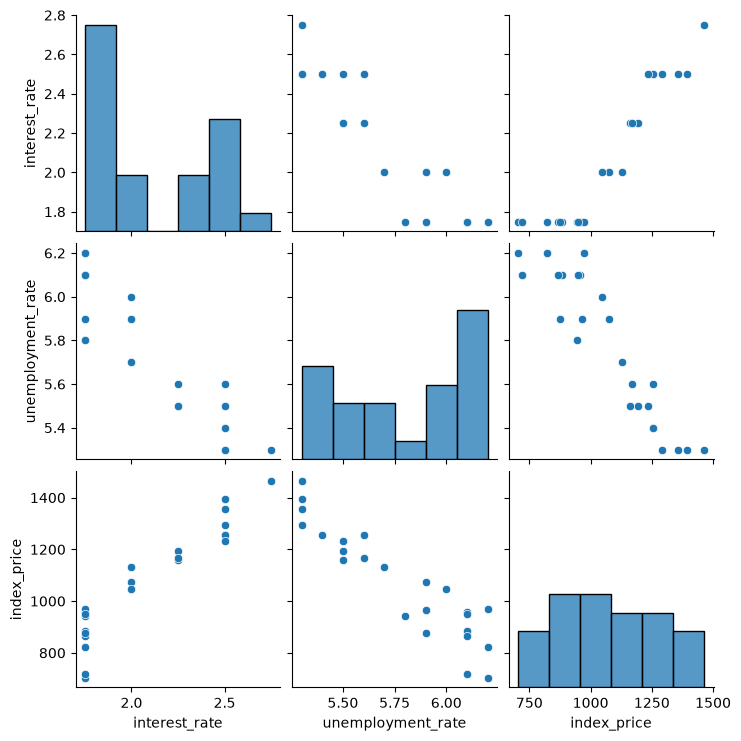

In [12]:
## lets do some visualization 
import seaborn as sns
sns.pairplot(df_index)

In [13]:
df_index.corr()

,interest_rate,unemployment_rate,index_price
interest_rate,1.000000,-0.925814,0.935793
unemployment_rate,-0.925814,1.000000,-0.922338
index_price,0.935793,-0.922338,1.000000


Text(0, 0.5, 'Unemployment rate')

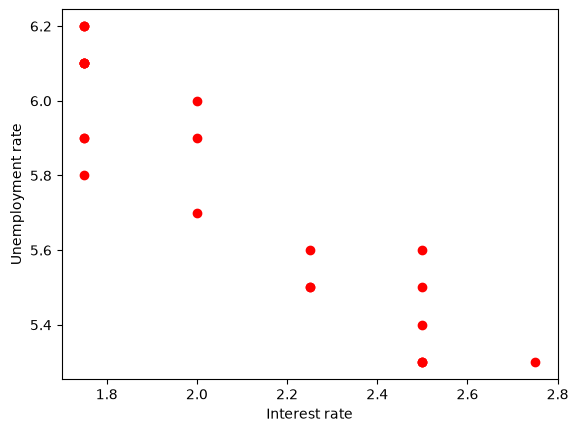

In [15]:
# index price will increase with increase in interest rate
# and descrease with increase in unemplyment rate
plt.scatter(df_index['interest_rate'],df_index['unemployment_rate'],color='r')
plt.xlabel('Interest rate')
plt.ylabel('Unemployment rate')

In [18]:
### get my independent and dependent feature
# X = df_index[['interest_rate','unemployment_rate']] 
X = df_index.iloc[:,:-1] # take everything except the last column
X.head()

,interest_rate,unemployment_rate
0,2.75,5.3
1,2.50,5.3
2,2.50,5.3
3,2.50,5.3
4,2.50,5.4


In [21]:
Y = df_index.iloc[:,-1] # take all the rows but in column just take one from last
Y.head()

0    1464
1    1394
2    1357
3    1293
4    1256
Name: index_price, dtype: int64

In [22]:
# train test split
from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_text = train_test_split(X,Y,test_size=0.25,random_state=42)

<Axes: xlabel='interest_rate', ylabel='index_price'>

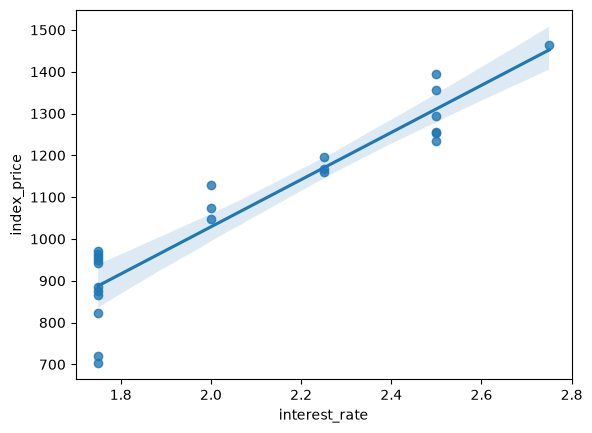

In [24]:
sns.regplot(x=df_index['interest_rate'],y=df_index['index_price'])

<Axes: xlabel='unemployment_rate', ylabel='index_price'>

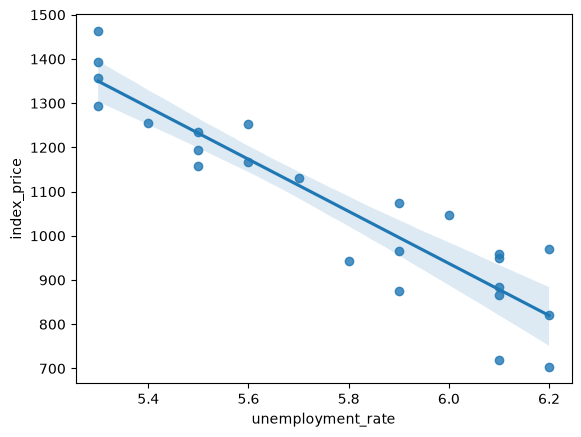

In [26]:
sns.regplot(x=df_index['unemployment_rate'],y=df_index['index_price'])

In [27]:
from sklearn.preprocessing import StandardScaler

In [28]:
scaler = StandardScaler()
X_train=scaler.fit_transform(X_train)
X_test=scaler.transform(X_test)

In [29]:
X_train

array([[-0.90115511,  0.37908503],
       [ 1.31077107, -1.48187786],
       [-0.90115511,  1.30956648],
       [ 1.31077107, -0.55139641],
       [ 1.31077107, -1.48187786],
       [-0.16384638,  0.68924552],
       [-0.90115511,  0.999406  ],
       [ 1.31077107, -1.48187786],
       [ 1.31077107, -1.17171738],
       [-0.90115511,  1.30956648],
       [-0.90115511,  0.999406  ],
       [-0.90115511,  0.37908503],
       [-0.90115511,  0.999406  ],
       [ 0.57346234, -0.8615569 ],
       [-0.16384638, -0.24123593],
       [-0.90115511,  0.06892455],
       [-0.90115511,  0.999406  ],
       [ 1.31077107, -0.8615569 ]])

In [31]:
from sklearn.linear_model import LinearRegression
regression = LinearRegression()

In [32]:
regression.fit(X_train,Y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](2,)","[ 88.27,-116.26]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,1053
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,2
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(2)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](2,)","[5.87,1.23]"


In [ ]:
from sklearn.model_selection import cross_val_score
validation_score = cross_val_score(regression,X_train,Y_train, scoring='neg_mean_squared_error',cv=3) # it gives 3 n-mse 
# We use cross_val_score to accurately estimate how well a machine learning model will generalize to unseen data
# for hyper tuning model - make it better  - we split the train data into train and validation and for that these use a algorithm in which we have to pass the cross validation value (assume if we provide 5 then in 1st step it take first 180(900/5 -  assuming we have 900 training dp) and use it to test then train in second step it take the next 180 data (leaving first 180 - start from 181) and then test using that and train with the left data, in 3rd step it take next 180 and so on )

In [ ]:
validation_score

array([-4921.61331265, -7686.87497294, -5135.9962549 ])

In [37]:
np.mean(validation_score)

np.float64(-5914.8281801623925)

In [38]:
Y_pred = regression.predict(X_test)

In [39]:
from sklearn.metrics import mean_absolute_error,mean_squared_error
mse = mean_squared_error(Y_text,Y_pred)
mae = mean_absolute_error(Y_text,Y_pred)
rmse = np.sqrt(mse)
print(mse) # it has penalized many outliers
print(mae)
print(rmse)

5793.7628877125835
59.9357815232356
76.11677139574815


In [40]:
from sklearn.metrics import r2_score
score = r2_score(Y_text,Y_pred)
score

0.8278978091457141

### Assumption 

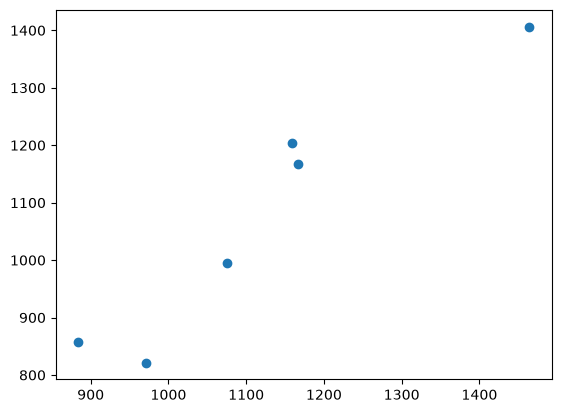

In [41]:
plt.scatter(Y_text,Y_pred)

In [42]:
residuals = Y_text-Y_pred
print(residuals)

8     -45.227704
16    149.349481
0      57.486996
18     26.291104
11     80.090077
9      -1.169327
Name: index_price, dtype: float64


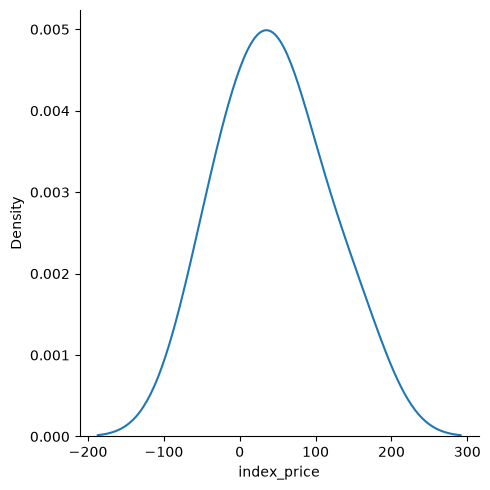

In [ ]:
sns.displot(residuals,kind='kde')
# the model says that model is good trained - normal distribution 

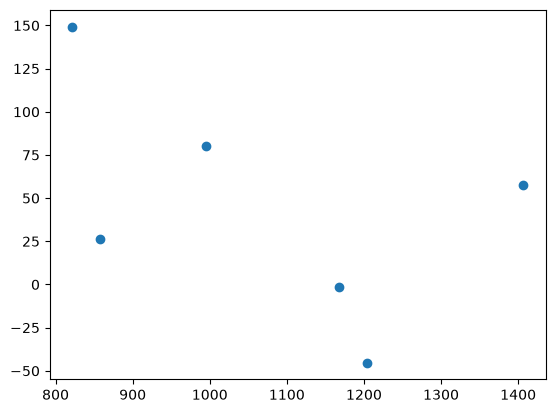

In [ ]:
plt.scatter(Y_pred,residuals)
# data is uniformly distributed - there is no such problem